<a href="https://colab.research.google.com/github/arambhaghimirecs24-stack/BIS/blob/main/1BF24CS062_Parallel_Cell_Algorithim/1BF24CS062_Parallel_Cell_Algorithim.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


Resolution: 256 x 256
Sequential Time: 0.00496 seconds
Parallel Time: 0.03357 seconds
Speedup: 0.15x

Resolution: 512 x 512
Sequential Time: 0.01795 seconds
Parallel Time: 0.04815 seconds
Speedup: 0.37x

Resolution: 1024 x 1024
Sequential Time: 0.04404 seconds
Parallel Time: 0.18493 seconds
Speedup: 0.24x


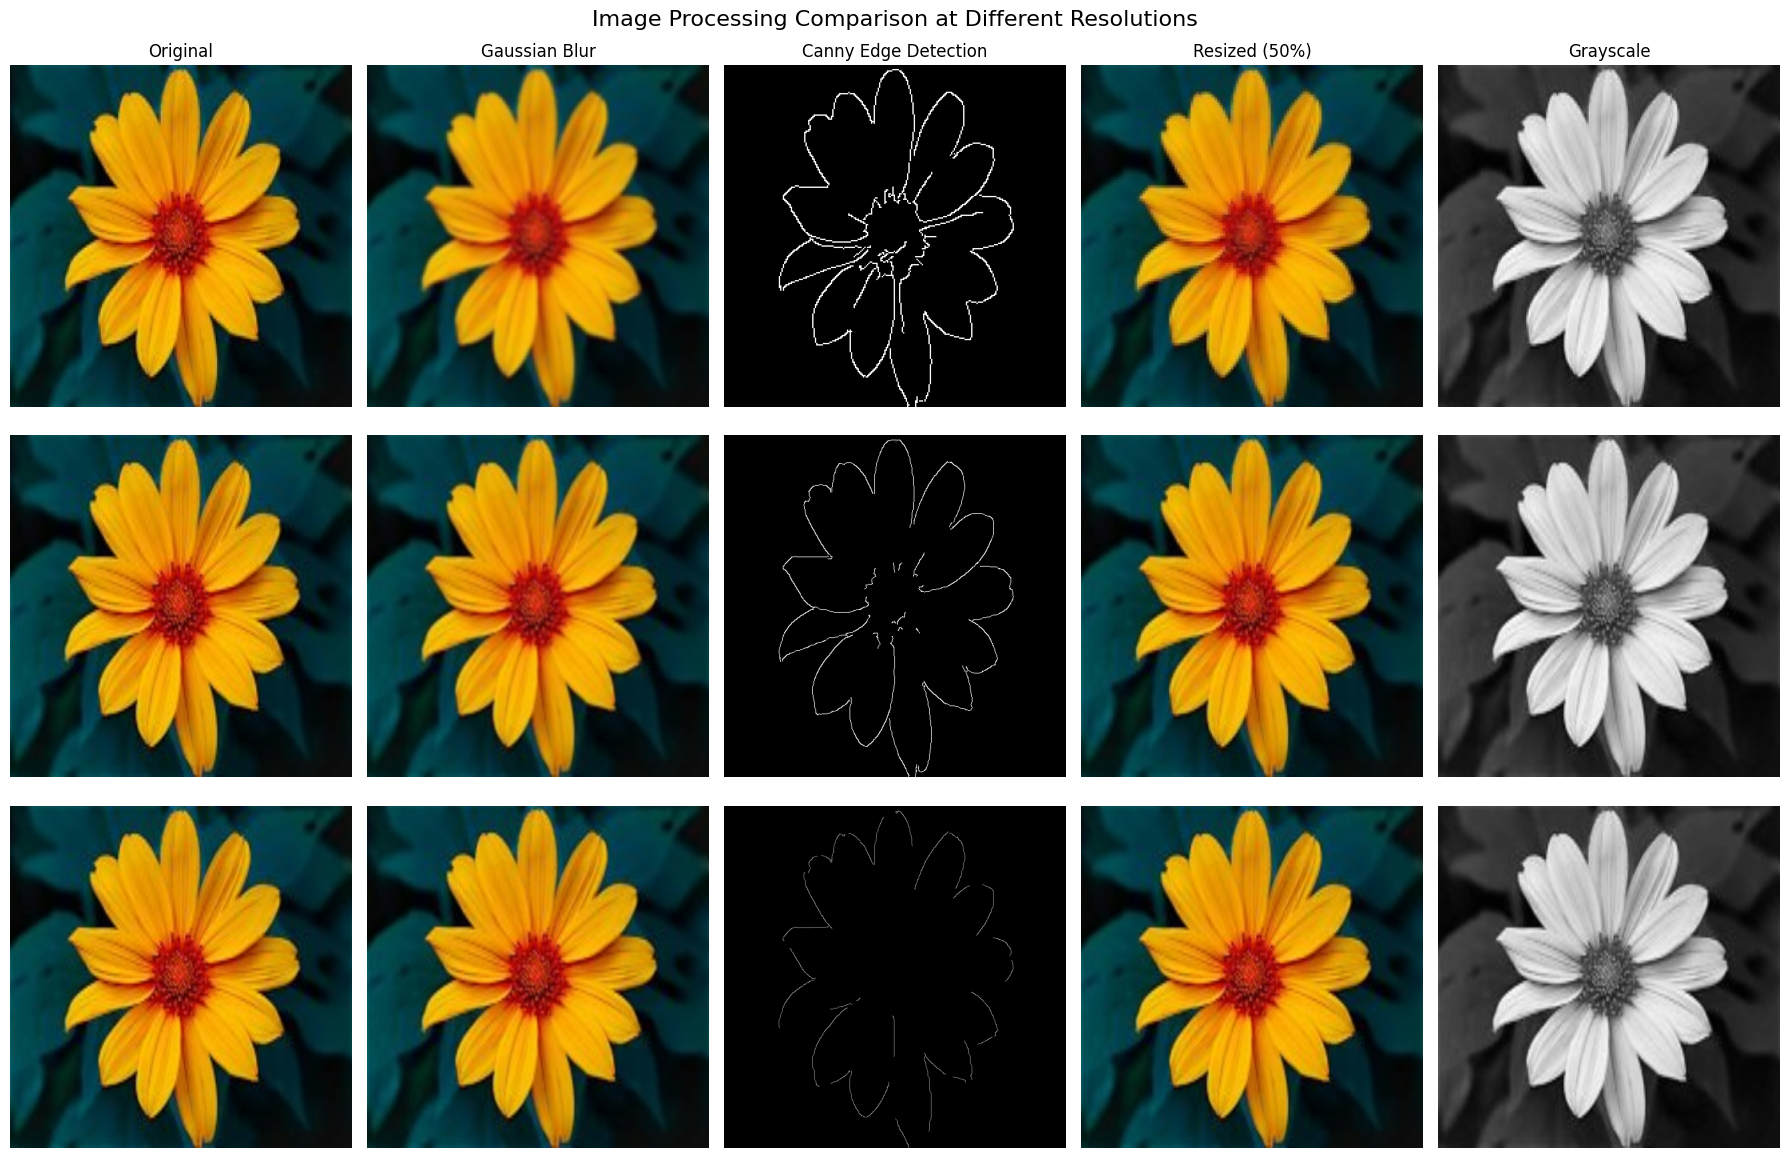

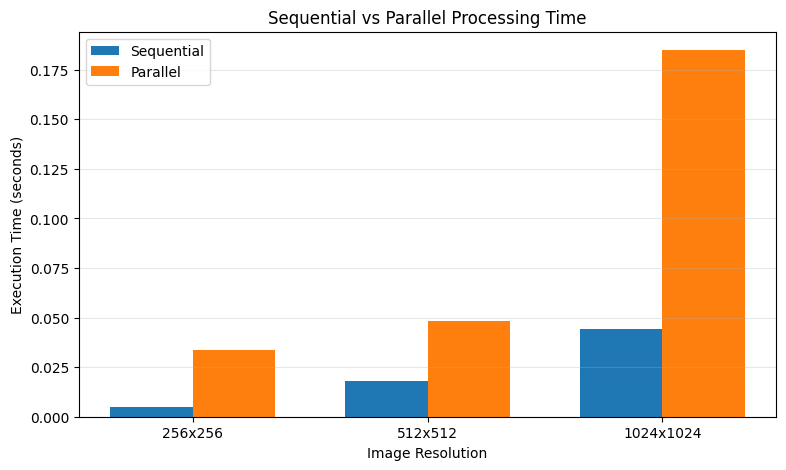

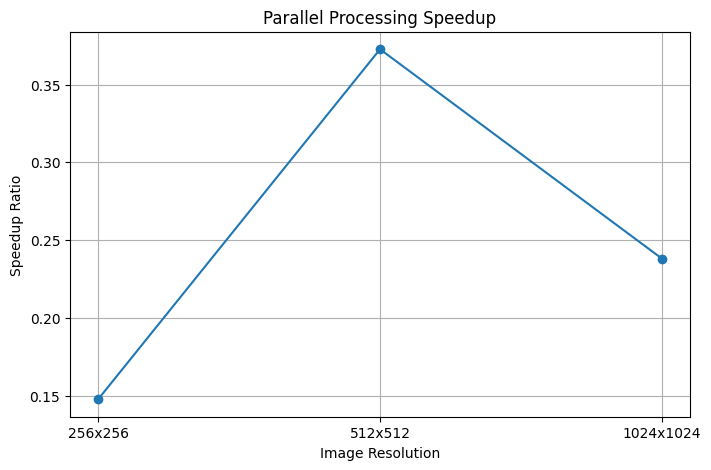

In [4]:

import cv2
import numpy as np
import matplotlib.pyplot as plt
import time
from joblib import Parallel, delayed

WORKERS = 2
RESOLUTIONS = [256, 512, 1024]
RUNS = 5

def sequential_processing(img):
    blurred = cv2.GaussianBlur(img, (5, 5), 0)
    edges = cv2.Canny(blurred, 100, 200)
    resized = cv2.resize(
        img, (img.shape[1] // 2, img.shape[0] // 2)
    )
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    return blurred, edges, resized, gray

def parallel_processing(img):
    blurred, resized, gray = Parallel(
        n_jobs=WORKERS,
        backend="loky"
    )([
        delayed(cv2.GaussianBlur)(img, (5, 5), 0),
        delayed(cv2.resize)(
            img, (img.shape[1] // 2, img.shape[0] // 2)
        ),
        delayed(cv2.cvtColor)(img, cv2.COLOR_BGR2GRAY)
    ])

    edges = cv2.Canny(blurred, 100, 200)

    return blurred, edges, resized, gray

single_times = []
parallel_times = []
speedups = []

# Store images for visual comparison
all_images = {}

for size in RESOLUTIONS:

    test_image = cv2.resize(image, (size, size))

    # Warm-up
    sequential_processing(test_image)
    parallel_processing(test_image)

    seq_results = []
    par_results = []

    for _ in range(RUNS):

        start = time.perf_counter()
        sequential_processing(test_image)
        seq_results.append(time.perf_counter() - start)

        start = time.perf_counter()
        parallel_processing(test_image)
        par_results.append(time.perf_counter() - start)

    single = np.mean(seq_results)
    parallel = np.mean(par_results)
    speedup = single / parallel

    single_times.append(single)
    parallel_times.append(parallel)
    speedups.append(speedup)

    # Save processed images
    all_images[size] = (
        test_image,
        *sequential_processing(test_image)
    )

    print(f"\nResolution: {size} x {size}")
    print(f"Sequential Time: {single:.5f} seconds")
    print(f"Parallel Time: {parallel:.5f} seconds")
    print(f"Speedup: {speedup:.2f}x")


# Display image comparison
titles = [
    "Original",
    "Gaussian Blur",
    "Canny Edge Detection",
    "Resized (50%)",
    "Grayscale"
]

fig, axes = plt.subplots(
    3, 5,
    figsize=(18, 12)
)

for row, size in enumerate(RESOLUTIONS):

    images = all_images[size]

    for col, img in enumerate(images):

        if col in [0, 1, 3]:
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        axes[row, col].imshow(
            img,
            cmap="gray" if col in [2, 4] else None
        )

        axes[row, col].axis("off")

        if row == 0:
            axes[row, col].set_title(titles[col])

        if col == 0:
            axes[row, col].set_ylabel(
                f"{size} x {size}",
                fontsize=12
            )

plt.suptitle(
    "Image Processing Comparison at Different Resolutions",
    fontsize=16
)

plt.tight_layout()
plt.show()


# Processing time comparison
x = np.arange(3)
width = 0.35

plt.figure(figsize=(9, 5))

plt.bar(
    x - width / 2,
    single_times,
    width,
    label="Sequential"
)

plt.bar(
    x + width / 2,
    parallel_times,
    width,
    label="Parallel"
)

plt.xticks(
    x,
    ["256x256", "512x512", "1024x1024"]
)

plt.xlabel("Image Resolution")
plt.ylabel("Execution Time (seconds)")
plt.title("Sequential vs Parallel Processing Time")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.show()


# Speedup graph
plt.figure(figsize=(8, 5))

plt.plot(
    ["256x256", "512x512", "1024x1024"],
    speedups,
    marker="o"
)

plt.xlabel("Image Resolution")
plt.ylabel("Speedup Ratio")
plt.title("Parallel Processing Speedup")
plt.grid()
plt.show()
